# Testing Notebook for Class Development

### Initialize dataset and stations / channels within it

In [2]:
%load_ext autoreload
%autoreload 2
%matplotlib widget


import os
os.chdir("/Users/nico/Documents/UCSB/research/LOBSTER")
from lobster_python import Dataset

In [3]:
dataset = Dataset(
    name="DemoORCA",
    data_dir="/Users/nico/Documents/UCSB/research/ORCA/DemoORCA",
    response_dir="/Users/nico/Documents/UCSB/research/ORCA/PacORCA_database/RESP",
    metadata_file="/Users/nico/Documents/UCSB/research/LOBSTER/examples/mockORCA/mockORCAdb.csv"
)

# Discover data and construct objects
dataset.scan()

# Inspect dataset
print("Stations:", dataset.list_stations())
print("Number of stations:", dataset.n_stations)

station = dataset.get_station("MM04")
print("Channels in MM04:", station.list_channels())

# Access a particular channel
channel = station.get_channel("CH0")

print("Waveform files for CH0:", channel.n_waveforms)
print("Response:", channel.response_file)

# Validate metadata and files
issues = dataset.validate()

for issue in issues:
    print("WARNING:", issue)

Stations: ['MM04', 'MM05', 'MM06', 'MM07', 'MM08', 'MM09']
Number of stations: 6
Channels in MM04: ['CH0', 'CH1', 'CH2', 'CH3']
Waveform files for CH0: 371
Response: /Users/nico/Documents/UCSB/research/ORCA/PacORCA_database/RESP/RESPfiles/CH0/RESP.P2.MM04..CH0


In [44]:
dataset.scan()

station = dataset.get_station("MM04")

print(station.latitude, station.longitude)
print(station.list_channels())

for channel in station.channels.values():
    print(
        channel.name,
        channel.n_waveforms,
        channel.response_file,
        channel.pz_file
    )

-34.090898477864 -154.125474098646
['CH0', 'CH1', 'CH2', 'CH3']
CH0 371 /Users/nico/Documents/UCSB/research/ORCA/PacORCA_database/RESP/RESPfiles/CH0/RESP.P2.MM04..CH0 /Users/nico/Documents/UCSB/research/ORCA/PacORCA_database/RESP/pzfiles/CH0/RESP.P2.MM04..CH0
CH1 371 /Users/nico/Documents/UCSB/research/ORCA/PacORCA_database/RESP/RESPfiles/CH1/RESP.P2.MM04..CH1 /Users/nico/Documents/UCSB/research/ORCA/PacORCA_database/RESP/pzfiles/CH1/RESP.P2.MM04..CH1
CH3 371 /Users/nico/Documents/UCSB/research/ORCA/PacORCA_database/RESP/RESPfiles/CH3/RESP.P2.MM04..CH3 /Users/nico/Documents/UCSB/research/ORCA/PacORCA_database/RESP/pzfiles/CH3/RESP.P2.MM04..CH3
CH2 371 /Users/nico/Documents/UCSB/research/ORCA/PacORCA_database/RESP/RESPfiles/CH2/RESP.P2.MM04..CH2 /Users/nico/Documents/UCSB/research/ORCA/PacORCA_database/RESP/pzfiles/CH2/RESP.P2.MM04..CH2


In [4]:
from lobster_python.processing import process_channel

station = dataset.get_station("MM04")
channel = station.get_channel("CH2")

process_channel(
    station,
    channel,
    output_dir="PSD_dir",
    remove_response=True
)

/opt/anaconda3/envs/seis/lib/python3.14/site-packages/obspy/io/xseed/parser.py:1398: UserWarning: Epoch XX.EE04.XX.CH2 [2011-12-02T00:00:00.000000Z - 2050-12-02T00:00:00.000000Z]: Response stage 1 does not end with blockette 58. Proceed at your own risk.
  warnings.warn(_epoch_warn_msg(msg))



Response file: /Users/nico/Documents/UCSB/research/ORCA/PacORCA_database/RESP/RESPfiles/CH2/RESP.P2.MM04..CH2
  - station: waveform='MM04', RESP='EE04'
Continuing with the assigned response file.


Response file: /Users/nico/Documents/UCSB/research/ORCA/PacORCA_database/RESP/RESPfiles/CH2/RESP.P2.MM04..CH2
  - station: waveform='MM04', RESP='EE04'
Continuing with the assigned response file.


Response file: /Users/nico/Documents/UCSB/research/ORCA/PacORCA_database/RESP/RESPfiles/CH2/RESP.P2.MM04..CH2
  - station: waveform='MM04', RESP='EE04'
Continuing with the assigned response file.


Response file: /Users/nico/Documents/UCSB/research/ORCA/PacORCA_database/RESP/RESPfiles/CH2/RESP.P2.MM04..CH2
  - station: waveform='MM04', RESP='EE04'
Continuing with the assigned response file.


Response file: /Users/nico/Documents/UCSB/research/ORCA/PacORCA_database/RESP/RESPfiles/CH2/RESP.P2.MM04..CH2
  - station: waveform='MM04', RESP='EE04'
Continuing with the assigned response file.


Response 

KeyboardInterrupt: 

<Figure size 640x480 with 0 Axes>

In [ ]:
with open(channel.response_file, "r") as f:
    for i, line in enumerate(f):
        if i >= 40:
            break
        print(line.rstrip())

#		<< IRIS SEED Reader, Release 5.2 >>
#
#		======== CHANNEL RESPONSE DATA ========
B050F03     Station:     EE04
B050F16     Network:     XX
B052F03     Location:    XX
B052F04     Channel:     CH0
B052F22     Start date:  2011,336,00:00:00.0000
B052F23     End date:    2050,336,00:00:00.0000
#		=======================================
#		+               +--------------------------------------------+                +
#		+               |   Response (Poles & Zeros),   B01 ch BHZ   |                +
#		+               +--------------------------------------------+                +
#
B053F03     Transfer function type:                A [Laplace Transform (Rad/sec)]
B053F04     Stage sequence number:                 1
B053F05     Response in units lookup:              M/S - velocity in meters per second
B053F06     Response out units lookup:             V - emf in volts
B053F07     A0 normalization factor:               2.316E+09
B053F08     Normalization frequency:               1
B053F0

In [12]:
channel_response = inventory[0][0][0].response

print("Instrument sensitivity:")
print(channel_response.instrument_sensitivity)

print("\nNumber of response stages:")
print(len(channel_response.response_stages))

for i, stage in enumerate(channel_response.response_stages, start=1):
    print(f"\nStage {i}")
    print("Stage gain:", stage.stage_gain)
    print("Stage gain frequency:", stage.stage_gain_frequency)
    print("Input units:", stage.input_units)
    print("Output units:", stage.output_units)
    print("Poles:", getattr(stage, "poles", None))
    print("Zeros:", getattr(stage, "zeros", None))

Instrument sensitivity:
Instrument Sensitivity:
	Value: 1459730000.0
	Frequency: 0.2
	Input units: M/S
	Input units description: Velocity in Meters per Second
	Output units: V
	Output units description: Volts


Number of response stages:
1

Stage 1
Stage gain: None
Stage gain frequency: None
Input units: M/S
Output units: V
Poles: [(-0.01815+0.01799j), (-0.01815-0.01799j), (-173+0j), (-196+231j), (-196-231j), (-732+1415j), (-732-1415j)]
Zeros: [0j, 0j, (-108+0j), (-161+0j)]


In [13]:
from obspy import read

test_trace = read(str(channel.waveform_files[0]))[0].copy()

# Make a copy so we don't modify the original inventory.
test_inventory = inventory.copy()

# The response belongs to EE04, but is being used for MM04.
test_inventory[0][0].code = test_trace.stats.station

test_trace.detrend("demean")
test_trace.detrend("linear")

test_trace.remove_response(
    inventory=test_inventory,
    output="VEL",
    pre_filt=(0.005, 0.01, 20.0, 25.0)
)

print(test_trace)

XX.MM04.XX.CH0 | 2019-11-18T03:30:59.309590Z - 2019-11-19T00:30:59.289590Z | 50.0 Hz, 3780000 samples


### psd workflow testing

/opt/anaconda3/envs/seis/lib/python3.14/site-packages/obspy/io/xseed/parser.py:1398: UserWarning: Epoch XX.EE04.XX.CH2 [2011-12-02T00:00:00.000000Z - 2050-12-02T00:00:00.000000Z]: Response stage 1 does not end with blockette 58. Proceed at your own risk.
  warnings.warn(_epoch_warn_msg(msg))


Current day is 2020-07-22T00:00:00.000000Z


/opt/anaconda3/envs/seis/lib/python3.14/site-packages/ipympl/backend_nbagg.py:342: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  self.figure.savefig(buf, format='png', dpi='figure')


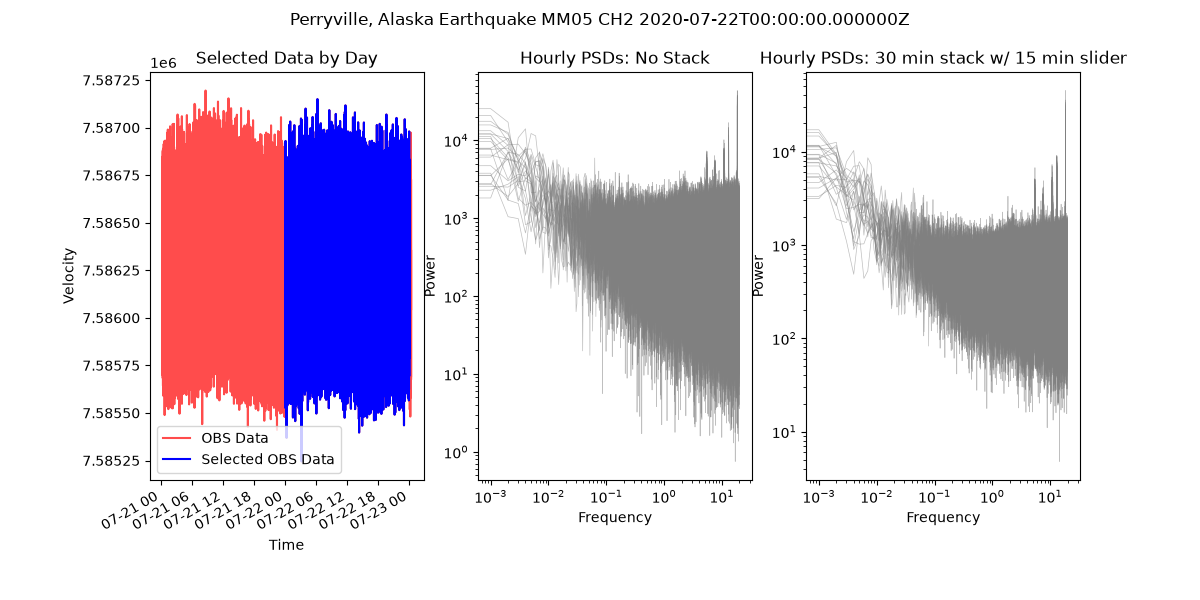

Current day is 2020-07-23T00:00:00.000000Z


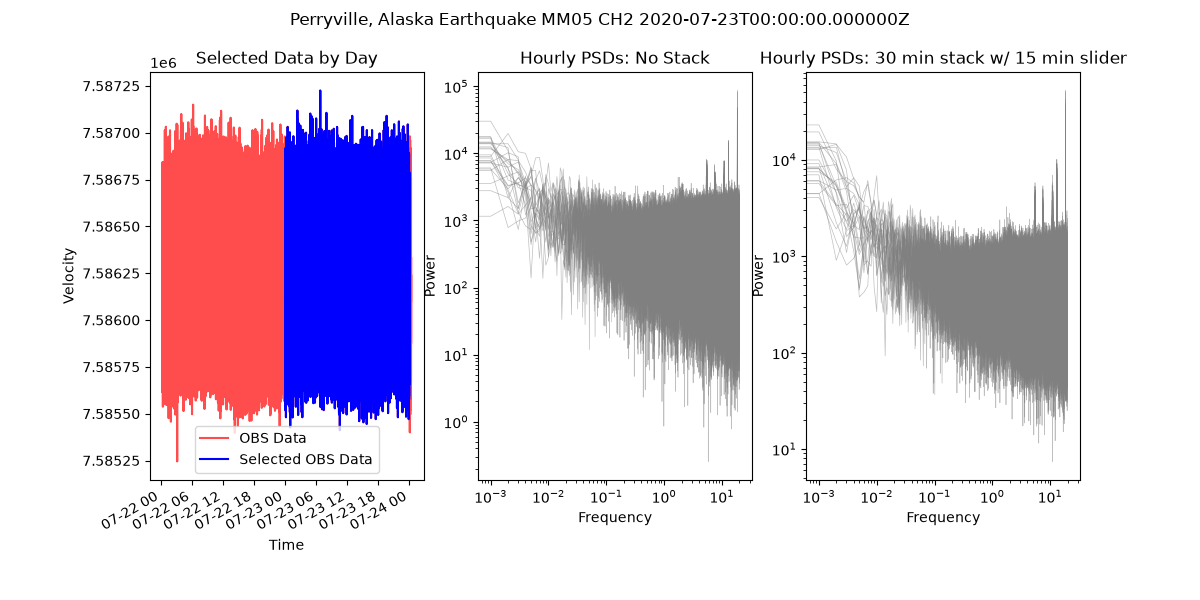

In [4]:
# successful UTCdatetime with data LOBSTER/PSD_dir/MM04/2019/11/19/4/CH0/PSD.pdf

from lobster_python.processing.response import extract_time_window , sliding_windows
from lobster_python.processing.psd import calculate_psd
from obspy import UTCDateTime, read_inventory, read
import numpy as np
import matplotlib.pyplot as plt

start_day = UTCDateTime("2020-07-22")
end_day = UTCDateTime("2020-07-23")

#identify station and channel (will be looped later)

station = dataset.get_station("MM05")
channel = station.get_channel("CH2")
inventory = read_inventory(str(channel.response_file),format="RESP")



for days in range(int((end_day - start_day) / 86400) + 1):
    plt.figure(figsize=(12,6))
    # print(days)
    current_day = start_day + days * 86400
    day_before = start_day + (days - 1) * 86400
    next_day = start_day + (days + 1) * 86400


    # print(f"Previous day is {day_before}")
    print(f"Current day is {current_day}")
    # print(f"Next day is {next_day}")

    plt.suptitle(f"Perryville, Alaska Earthquake {station.name} {channel.name} {current_day}")

    files = channel.get_waveform_files(
        starttime=day_before,
        endtime=next_day
    )

    # print(files)

    st = read(files[0])
    for file in files[1:]:
        st += read(file)

    st.merge(method=1, fill_value=None)
    tr = st[0]
    day_of_data = extract_time_window(tr,starttime=current_day,endtime=next_day) 


    data = tr.data
    times = tr.times("matplotlib")

    data2 = day_of_data.data
    times2 = day_of_data.times("matplotlib")
    plt.subplot(1,3,1)
    plt.plot(times,data,c='r',alpha=0.7,label='OBS Data')
    plt.plot(times2,data2,c='b',label='Selected OBS Data')

    plt.gca().xaxis_date()
    plt.gcf().autofmt_xdate()
    plt.xlabel("Time")
    plt.ylabel("Velocity")
    plt.title("Selected Data by Day")
    plt.legend()

    # plt.show()

#     st = read(files[0])
#     st += read(files[1])

# st.merge(method=1, fill_value=None)
    # print(st[0])
    # plt.figure(figsize=(8,6))

    median_stds = []
    stds = []

    for hours in range(int((next_day-current_day)/ 3600)+1)[:-1]:
        # print(hours)
        current_hour = current_day + hours * 3600
        next_hour = current_day + (hours+1) * 3600
        # print(current_hour,next_hour)
        hour_of_data = extract_time_window(tr,starttime=current_hour,endtime=next_hour) 

        psds = []
        for window_trace in sliding_windows(hour_of_data,window_minutes=30):
            

            psd = calculate_psd(window_trace,sampling_rate=window_trace.stats.sampling_rate)
            psds.append(psd[1])

        psds = np.array(psds)
        median_psd = np.median(psds, axis=0)

        std_median = np.std(median_psd)
        std = np.std(psd)

        median_stds.append(std_median)
        stds.append(std)



        # print(std_median,std)

        plt.subplot(1,3,2)
        plt.loglog(psd[0],psd[1],c='grey',linewidth=0.5,alpha=0.5)
        plt.xlabel("Frequency")
        plt.ylabel("Power")
        plt.title("Hourly PSDs: No Stack")

        plt.subplot(1,3,3)
        plt.loglog(psd[0],median_psd,c='grey',linewidth=0.5,alpha=0.5)
        plt.xlabel("Frequency")
        plt.ylabel("Power")
        plt.title("Hourly PSDs: 30 min stack w/ 15 min slider")

    plt.show()












In [15]:
# trace = read(str(channel.waveform_files[0]))[0]

# trace

type(day_of_data)

obspy.core.trace.Trace

In [40]:
# channel.waveform_files

start_day = UTCDateTime("2019-11-20")
end_day = UTCDateTime("2019-11-24")

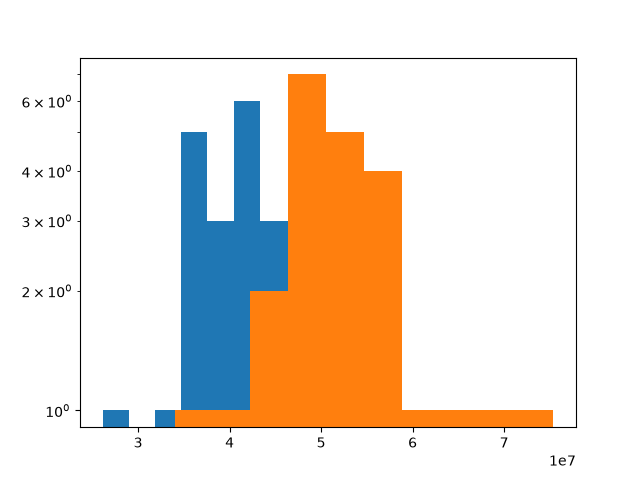

In [13]:
plt.figure()
plt.hist(stds,log=True)
plt.hist(median_stds,log=True)
plt.show()

In [ ]:
# successful UTCdatetime with data LOBSTER/PSD_dir/MM04/2019/11/19/4/CH0/PSD.pdf

from lobster_python.processing.response import extract_time_window , sliding_windows
from lobster_python.processing.psd import calculate_psd
from obspy import UTCDateTime, read_inventory, read
import numpy as np
import matplotlib.pyplot as plt

start_day = UTCDateTime("2020-07-22")
end_day = UTCDateTime("2020-07-23")

#identify station and channel (will be looped later)

station = dataset.get_station("MM05")
channel = station.get_channel("CH2")
inventory = read_inventory(str(channel.response_file),format="RESP")



for days in range(int((end_day - start_day) / 86400) + 1):
    plt.figure(figsize=(12,6))
    # print(days)
    current_day = start_day + days * 86400
    day_before = start_day + (days - 1) * 86400
    next_day = start_day + (days + 1) * 86400


    # print(f"Previous day is {day_before}")
    print(f"Current day is {current_day}")
    # print(f"Next day is {next_day}")

    plt.suptitle(f"Perryville, Alaska Earthquake {station.name} {channel.name} {current_day}")

    files = channel.get_waveform_files(
        starttime=day_before,
        endtime=next_day
    )

    # print(files)

    st = read(files[0])
    for file in files[1:]:
        st += read(file)

    st.merge(method=1, fill_value=None)
    tr = st[0]
    day_of_data = extract_time_window(tr,starttime=current_day,endtime=next_day) 


    data = tr.data
    times = tr.times("matplotlib")

    data2 = day_of_data.data
    times2 = day_of_data.times("matplotlib")
    plt.subplot(1,3,1)
    plt.plot(times,data,c='r',alpha=0.7,label='OBS Data')
    plt.plot(times2,data2,c='b',label='Selected OBS Data')

    plt.gca().xaxis_date()
    plt.gcf().autofmt_xdate()
    plt.xlabel("Time")
    plt.ylabel("Velocity")
    plt.title("Selected Data by Day")
    plt.legend()

    # plt.show()

#     st = read(files[0])
#     st += read(files[1])

# st.merge(method=1, fill_value=None)
    # print(st[0])
    # plt.figure(figsize=(8,6))

    median_stds = []
    stds = []

    for hours in range(int((next_day-current_day)/ 3600)+1)[:-1]:
        # print(hours)
        current_hour = current_day + hours * 3600
        next_hour = current_day + (hours+1) * 3600
        # print(current_hour,next_hour)
        hour_of_data = extract_time_window(tr,starttime=current_hour,endtime=next_hour) 

        psds = []
        for window_trace in sliding_windows(hour_of_data,window_minutes=30):
            

            psd = calculate_psd(window_trace,sampling_rate=window_trace.stats.sampling_rate)
            psds.append(psd[1])

        psds = np.array(psds)
        median_psd = np.median(psds, axis=0)

        std_median = np.std(median_psd)
        std = np.std(psd)

        median_stds.append(std_median)
        stds.append(std)



        # print(std_median,std)

        plt.subplot(1,3,2)
        plt.loglog(psd[0],psd[1],c='grey',linewidth=0.5,alpha=0.5)
        plt.xlabel("Frequency")
        plt.ylabel("Power")
        plt.title("Hourly PSDs: No Stack")

        plt.subplot(1,3,3)
        plt.loglog(psd[0],median_psd,c='grey',linewidth=0.5,alpha=0.5)
        plt.xlabel("Frequency")
        plt.ylabel("Power")
        plt.title("Hourly PSDs: 30 min stack w/ 15 min slider")

    plt.show()










